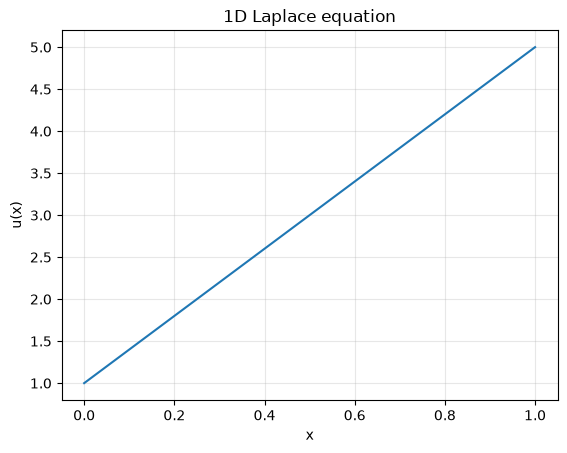

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1D Laplace, u(0) = 1, u(1) = 5
N = 100
x = np.linspace(0, 1, N)
A = -2 * np.diag(np.ones(N - 2)) + np.diag(np.ones(N - 3), 1) + np.diag(np.ones(N - 3), -1)
b = np.zeros(N - 2)
b[0], b[-1] = -1.0, -5.0

u = np.linalg.solve(A, b)
u = np.concatenate(([1.0], u, [5.0]))
plt.plot(x, u)
plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("1D Laplace equation")
plt.grid(alpha=0.3)
plt.show()


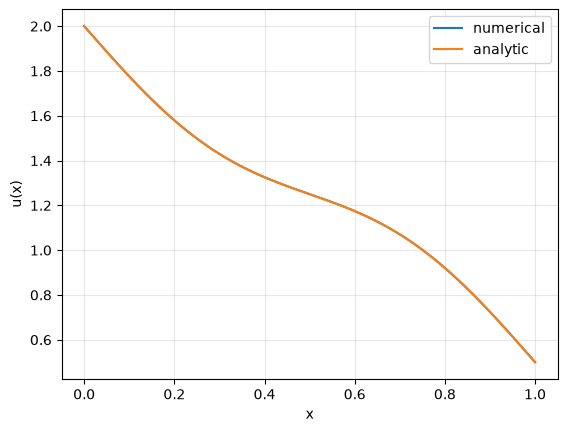

In [2]:
# 1D Poisson, u(0) = 2, u(1) = 0.5
f = lambda x: 5 * np.sin(2 * np.pi * x)
N = 1000
x = np.linspace(0, 1, N)
dx = x[1] - x[0]

A = -2 * np.diag(np.ones(N - 2)) + np.diag(np.ones(N - 3), 1) + np.diag(np.ones(N - 3), -1)
b = f(x[1:-1]) * dx**2
b[0] -= 2.0
b[-1] -= 0.5

u = np.linalg.solve(A, b)
u = np.concatenate(([2.0], u, [0.5]))

plt.plot(x, u, label="numerical")
plt.plot(x, -5 / (4 * np.pi**2) * np.sin(2 * np.pi * x) - 1.5 * x + 2, label="analytic")
plt.xlabel("x")
plt.ylabel("u(x)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


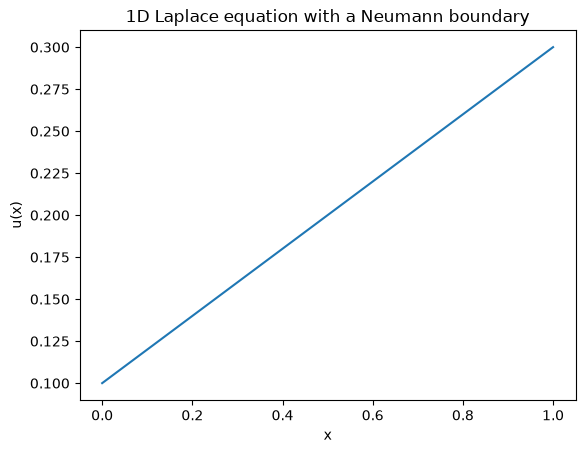

In [3]:
# 1D Laplace with Von Neumann left boundary
alpha = 0.2
beta = 0.3

N = 100
x = np.linspace(0, 1, N)
h = x[1] - x[0]

# Unknowns u_0, ..., u_{N-1}. The first row is the Neumann condition
# u'(0) = alpha, interior rows use the three-point Laplace stencil, and the
# last row is the Dirichlet condition u(1) = beta.
A = np.zeros((N, N))
b = np.zeros(N)
A[0, 0], A[0, 1] = -1.0, 1.0
b[0] = alpha * h
for i in range(1, N - 1):
    A[i, i - 1] = 1.0
    A[i, i] = -2.0
    A[i, i + 1] = 1.0
A[-1, -1] = 1.0
b[-1] = beta

u = np.linalg.solve(A, b)
plt.plot(x, u)
plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("1D Laplace equation with a Neumann boundary")
plt.show()

# 6.71

interior temperatures: [0.2 0.4 0.6 0.8]


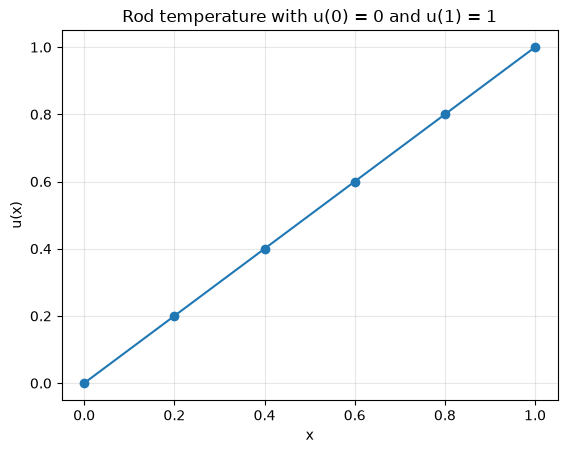

In [4]:
# Exercise 6.71: a 1D rod with four interior nodes.
n = 5                      # number of subintervals
h = 1 / n
u_left, u_right = 0.0, 1.0

A = np.diag(-2 * np.ones(n - 1))
A += np.diag(np.ones(n - 2), 1) + np.diag(np.ones(n - 2), -1)
b = np.zeros(n - 1)
b[0] = -u_left
b[-1] = -u_right

interior = np.linalg.solve(A, b)
u = np.concatenate(([u_left], interior, [u_right]))
print("interior temperatures:", np.round(interior, 6))

x = np.linspace(0, 1, n + 1)
plt.plot(x, u, "o-")
plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("Rod temperature with u(0) = 0 and u(1) = 1")
plt.grid(alpha=0.3)
plt.show()


# 6.67

## a.
The temperature of the left end is $u(x) = 0$ and the right end is $u(1) = 1$. The integration $u_{xx} = 0$

## b.
$\begin{bmatrix}
-2 & 1 & 0 & 0\\
1 & -2 & 1 & 0\\
0 & 1 & -2 & 1\\
0 & 0 & 1 & -2
\end{bmatrix}=\begin{bmatrix}
0\\ 
0\\
0\\ 
0
\end{bmatrix}$

## c.
I'm confused with this question and I probably misunderstand something since I didn't see the difference



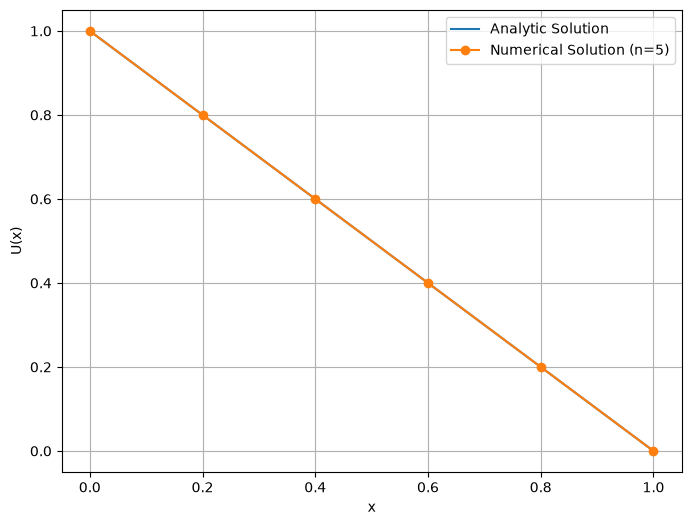

In [5]:

def analytic_solution(x):
    return 1 - x

def numerical_solution(n_intervals):
    n_points = n_intervals + 1
    x = np.linspace(0, 1, n_points)
    
    # Construct the coefficient matrix A
    A = np.zeros((n_points-2, n_points-2))
    for i in range(n_points-2):
        A[i, i] = -2
        if i > 0:
            A[i, i-1] = 1
        if i < n_points-3:
            A[i, i+1] = 1
    
    # Construct the right-hand side vector b
    b = np.zeros(n_points-2)
    b[0] = -1
    
    # Solve the linear system
    U = np.zeros(n_points)
    U[0] = 1
    U[-1] = 0
    U[1:-1] = np.linalg.solve(A, b)
    
    return x, U

# Compare analytic and numerical solutions
n_intervals = 5
x_analytic = np.linspace(0, 1, 100)
U_analytic = analytic_solution(x_analytic)

x_numerical, U_numerical = numerical_solution(n_intervals)

plt.figure(figsize=(8, 6))
plt.plot(x_analytic, U_analytic, label="Analytic Solution")
plt.plot(x_numerical, U_numerical, 'o-', label=f"Numerical Solution (n={n_intervals})")
plt.xlabel("x")
plt.ylabel("U(x)")
plt.legend()
plt.grid(True)
plt.show()

# 6.70

I got no ideas what's really different from the Laplace equation, except the right hand side of the matrix equation to be some functions.

## Feeling needs much more help to understand the content this time!!!